# Part 2. Exploratory analysis and feature engineering

**Project question.** An expressway link is moving normally now. Will it be unusually slow 15 minutes later?

This notebook explores the model table built in Part 1 and builds the extra inputs for the models. It uses the
**train and validation days only** (16 Oct - 13 Nov); the test week is never opened here. It answers the questions
that shaped the label, the inputs and the evaluation:

1. Is the collection complete enough, and where are the gaps?
2. Is "slow" the same as "unusual"? (Why the label compares a link with its own normal level.)
3. How rare are onsets, and how do they vary by hour, road and week?
4. How long do unusual episodes last, and how dependent are the rows? (The effective sample size.)
5. How do rain and the weeks differ?
6. **Feature engineering:** which inputs do we add to the build's 53, and are they built correctly?
7. What comes before an onset? (Why these inputs should help.)
8. What kinds of onset are there, judged only by what is known at the time of the prediction?

Maps and time-space diagrams of the raw speed bands are in `03_visuals.ipynb` (project folder).

To run: open this notebook from the `notebooks/` folder with the project's Python environment (about 2 minutes). It
needs the model tables (Part 1). It writes only figures: `figures/notebooks/part2_*.png` and the report's first figure,
`figures/report/report_fig1_exploration.png`.

*AI use: code and text drafted with Claude (Anthropic) on 28 Nov 2026. Every number is computed from the data below;
the engineered inputs are checked in section 6, including an independent recomputation.*

In [1]:
import os, sys, time, json, random
from datetime import date, datetime, timedelta
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display

HERE = Path.cwd()                 # notebooks/
ROOT = HERE.parent                # the project folder
sys.path.insert(0, str(ROOT / "modelling"))
import settings as S              # dates and file locations of the modelling pipeline
import features as F              # the engineered inputs

FIG = ROOT / "figures" / "notebooks"      # the figures this notebook draws
REPORT_FIG = ROOT / "figures" / "report"   # the figures used in the report
PIPE_FIG = ROOT / "figures" / "pipeline"   # the figures drawn by the scripts in modelling/
for folder in (FIG, REPORT_FIG):
    folder.mkdir(parents=True, exist_ok=True)
T0 = time.time()
def log(msg):
    print(f"[{time.time() - T0:5.0f} s] {msg}", flush=True)

def mdtable(rows, header):
    """Show a small table as Markdown."""
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK2, MUTED, GRID, SURFACE = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig((REPORT_FIG if name.startswith("report_") else FIG) / name)
    plt.show()

pl.Config.set_tbl_rows(14)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True)

LAST = S.LAST_OPEN_DAY                     # Fri 13 Nov: nothing after this day is read
links = pl.read_parquet(S.LINKS)
ids = links["LinkID"].to_list()
full = (pl.scan_parquet(S.FULL).filter(pl.col("in_population"))       # weekdays without public holidays
          .select("LinkID", "road", "heldout_road", "t", "date", "split", "use", "U", "y", "info_band",
                  "info_norm_band", "info_deficit", "f_d0", "f_d5", "f_d10", "f_dn_d0", "f_up_d0", "f_slot15",
                  "f_rain30", "f_rain30_missing")
          .collect())
assert full["date"].max() <= LAST
tr = full.filter(pl.col("split") == "train")
use = full.filter(pl.col("use"))
print(f"{full.height:,} weekday rows (all, also unusable) on {full['date'].n_unique()} days; "
      f"{use.height:,} usable; {links.height:,} links")

9,976,320 weekday rows (all, also unusable) on 20 days; 8,048,388 usable; 2,598 links


## 1. Collection completeness

Share of the 2,598 expressway links' 5-minute updates captured, for every hour of every day (the box marks
06:00-22:00, the hours the rows use).

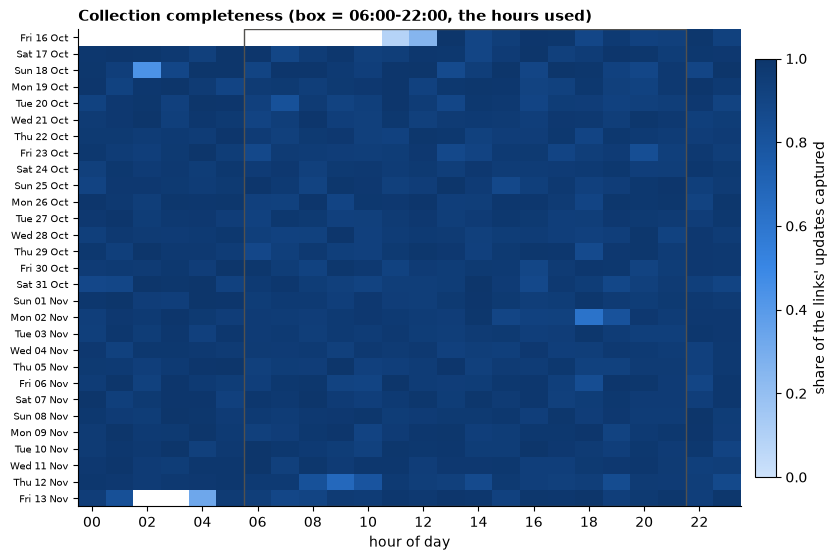

06:00-22:00: median hour 0.959; lowest hour 0.083 (Fri 16 Oct)


In [2]:
panel = (pl.scan_parquet(S.PANEL).filter(pl.col("LinkID").is_in(ids) & (pl.col("t").dt.date() <= LAST))
           .group_by(pl.col("t").dt.date().alias("date"), pl.col("t").dt.hour().alias("hour")).len().collect())
days_all = [S.TRAIN_DAYS[0] + timedelta(days=i) for i in range((LAST - S.TRAIN_DAYS[0]).days + 1)]
grid = np.full((len(days_all), 24), np.nan)
for d, h, n in panel.iter_rows():
    grid[days_all.index(d), h] = n / (len(ids) * 12)
fig, ax = plt.subplots(figsize=(9, 6.2))
im = ax.imshow(grid, aspect="auto", cmap=BLUES, vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(days_all)))
ax.set_yticklabels([f"{d:%a %d %b}" for d in days_all], fontsize=7)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("hour of day")
ax.grid(False)
ax.add_patch(plt.Rectangle((5.5, -0.5), 16, len(days_all), fill=False, edgecolor=INK2, linewidth=1))
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("share of the links' updates captured")
ax.set_title("Collection completeness (box = 06:00-22:00, the hours used)")
save(fig, "part2_completeness.png")
in_win = grid[:, 6:22]
print(f"06:00-22:00: median hour {np.nanmedian(in_win):.3f}; lowest hour {np.nanmin(in_win):.3f} "
      f"({days_all[int(np.nanargmin(in_win) // 16)]:%a %d %b})")

Most hours are nearly complete: the median hour between 06:00 and 22:00 has 96% of its updates. Fri 16 Oct starts at
11:10 (collection began then) and Thu 12 Nov is thinner (the second collector was down). Missing updates are never
filled in beyond 5 minutes; rows that need a missing update are left out (Part 1, step 5), so the gaps make rows
unusable but never wrong.

## 2. Slow is not the same as unusual

A link that crawls every evening is slow, but not unusual. The label therefore compares each link with **its own
normal level** (the median band in that 15-minute slot over the train weekdays).

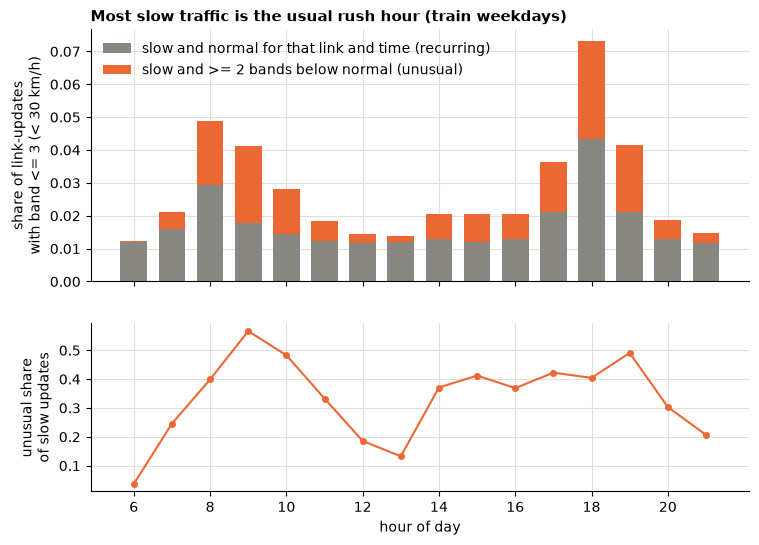

slow link-updates (band <= 3): 61.7% recurring, 38.3% unusual


In [3]:
slow = (tr.filter(pl.col("info_band").is_not_null()).group_by(pl.col("t").dt.hour().alias("hour"))
          .agg(pl.len().alias("n"),
               ((pl.col("info_band") <= 3) & (pl.col("info_deficit") < 2)).sum().alias("recurring"),
               ((pl.col("info_band") <= 3) & (pl.col("info_deficit") >= 2)).sum().alias("unusual"))
          .sort("hour"))
h = slow["hour"].to_numpy()
rec, unu = (slow["recurring"] / slow["n"]).to_numpy(), (slow["unusual"] / slow["n"]).to_numpy()
fig, axs = plt.subplots(2, 1, figsize=(8.5, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
axs[0].bar(h, rec, width=0.7, color=MUTED, label="slow and normal for that link and time (recurring)")
axs[0].bar(h, unu, bottom=rec, width=0.7, color=SLOT[1], label="slow and >= 2 bands below normal (unusual)")
axs[0].set_ylabel("share of link-updates\nwith band <= 3 (< 30 km/h)")
axs[0].legend(loc="upper left")
axs[0].set_title("Most slow traffic is the usual rush hour (train weekdays)")
axs[1].plot(h, unu / (rec + unu), color=SLOT[1], marker="o", markersize=4)
axs[1].set_ylabel("unusual share\nof slow updates")
axs[1].set_xlabel("hour of day")
axs[1].set_xticks(range(6, 22, 2))
save(fig, "part2_recurring_vs_unusual.png")
tot = slow["recurring"].sum() + slow["unusual"].sum()
print(f"slow link-updates (band <= 3): {slow['recurring'].sum() / tot:.1%} recurring, {slow['unusual'].sum() / tot:.1%} unusual")

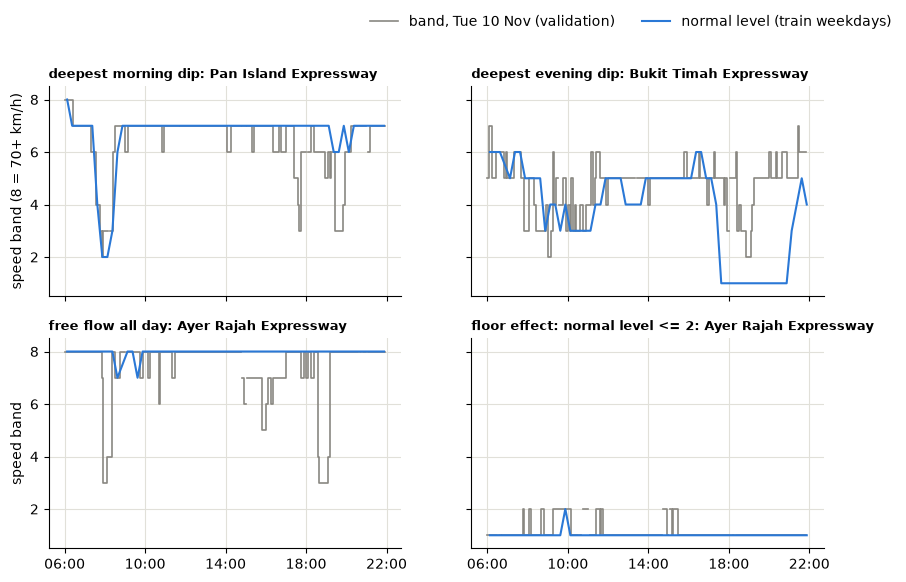

floor effect: 0.62% of weekday link x slot cells have a normal level of band 1-2 (a drop of 2 is impossible there); 7 links sit at band <= 2 all day


In [4]:
norm_w = pl.read_parquet(S.NORM).filter(pl.col("daytype") == "weekday")
prof = (norm_w.filter(pl.col("slot15").is_between(24, 87)).group_by("LinkID")
              .agg(pl.col("norm_band").min().alias("mn"),
                   pl.col("norm_band").filter(pl.col("slot15").is_between(28, 39)).min().alias("am"),
                   pl.col("norm_band").filter(pl.col("slot15").is_between(68, 79)).min().alias("pm"),
                   pl.col("norm_band").max().alias("mx"))
              .join(links.select("LinkID", "road"), on="LinkID"))
free = prof.filter(pl.col("mx") >= 6)
pick = [free.sort(["am", "LinkID"]).row(0, named=True), free.sort(["pm", "LinkID"]).row(0, named=True),
        prof.filter(pl.col("mn") >= 7).sort("LinkID").row(0, named=True),
        prof.filter(pl.col("mx") <= 2).sort("LinkID").row(0, named=True)]
titles = ["deepest morning dip", "deepest evening dip", "free flow all day", "floor effect: normal level <= 2"]
day = date(2026, 11, 10)
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, p, ttl in zip(axs.ravel(), pick, titles):
    n = norm_w.filter((pl.col("LinkID") == p["LinkID"]) & pl.col("slot15").is_between(24, 87)).sort("slot15")
    b = full.filter((pl.col("LinkID") == p["LinkID"]) & (pl.col("date") == day)).sort("t")
    x = (b["t"].dt.hour() * 4 + b["t"].dt.minute() / 15).to_numpy()
    ax.step(x, b["info_band"].to_numpy(), where="post", color=MUTED, linewidth=1.2, label="band, Tue 10 Nov (validation)")
    ax.plot(n["slot15"].to_numpy() + 0.5, n["norm_band"].to_numpy(), color=SLOT[0], label="normal level (train weekdays)")
    ax.set_title(f"{ttl}: {p['road'].title()}", fontsize=9)
    ax.set_xticks(range(24, 89, 16))
    ax.set_xticklabels([f"{t // 4:02d}:00" for t in range(24, 89, 16)])
    ax.set_ylim(0.5, 8.5)
axs[0, 0].set_ylabel("speed band (8 = 70+ km/h)")
axs[1, 0].set_ylabel("speed band")
hnd, lab = axs[0, 0].get_legend_handles_labels()
fig.legend(hnd, lab, loc="upper right", ncol=2, bbox_to_anchor=(0.98, 1.02))
save(fig, "part2_norm_examples.png")
floor = norm_w.filter(pl.col("slot15").is_between(24, 87))
print(f"floor effect: {floor.filter(pl.col('norm_band') <= 2).height / floor.height:.2%} of weekday link x slot cells "
      f"have a normal level of band 1-2 (a drop of 2 is impossible there); {prof.filter(pl.col('mx') <= 2).height} "
      "links sit at band <= 2 all day")

About 6 in 10 slow link-updates are the usual rush hour, so a plain "slow traffic" detector would mostly rediscover
rush hour. The normal level absorbs each link's own peaks. Its blind spot is small: where a link is normally at band 1-2
(under 0.7% of cells), a 2-band drop cannot happen, so unusual events inside heavy everyday congestion are not labelled.

## 3. How rare are onsets?

An **onset row** is a row that is normal now (U = False); it is positive when the link is unusual 15 minutes later.

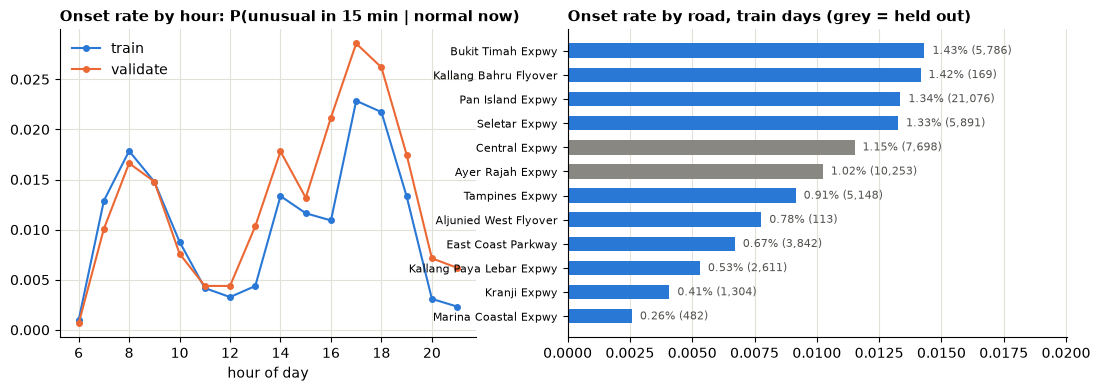

period,rows normal now,onsets,onset rate
str,u32,u32,f64
"""10-13 Nov (validation)""",1178466,13883,0.0118
"""16-23 Oct (train)""",1623401,10146,0.0062
"""26 Oct - 6 Nov (train)""",2963150,36276,0.0122


In [5]:
byh = (use.group_by("split", (pl.col("f_slot15") // 4).alias("hour"))
          .agg(pl.col("U").mean().alias("share_U"), pl.col("y").filter(~pl.col("U")).mean().alias("onset_rate"))
          .sort("split", "hour"))
road = (use.filter(~pl.col("U")).group_by("road", "heldout_road", "split")
           .agg(pl.col("y").mean().alias("rate"), pl.len().alias("rows"), pl.col("y").sum().alias("onsets"))
           .sort("road"))
rt = road.filter(pl.col("split") == "train").sort("rate")
fig, axs = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.2]})
for sp, c in (("train", SLOT[0]), ("validate", SLOT[1])):
    d = byh.filter(pl.col("split") == sp)
    axs[0].plot(d["hour"], d["onset_rate"], color=c, marker="o", markersize=4, label=sp)
axs[0].set_title("Onset rate by hour: P(unusual in 15 min | normal now)")
axs[0].set_xlabel("hour of day")
axs[0].set_xticks(range(6, 22, 2))
axs[0].legend()
cols = [MUTED if hr else SLOT[0] for hr in rt["heldout_road"]]
axs[1].barh(range(rt.height), rt["rate"].to_numpy(), color=cols, height=0.6)
axs[1].set_yticks(range(rt.height))
axs[1].set_yticklabels([r.title().replace("Expressway", "Expwy") for r in rt["road"]], fontsize=8)
for i, (v, n) in enumerate(zip(rt["rate"], rt["onsets"])):
    axs[1].text(v, i, f"  {v:.2%} ({n:,})", va="center", fontsize=8, color=INK2)
axs[1].set_xlim(0, rt["rate"].max() * 1.4)
axs[1].set_title("Onset rate by road, train days (grey = held out)")
axs[1].grid(axis="y", visible=False)
save(fig, "part2_onset_rate.png")
per = (use.filter(~pl.col("U") & ~pl.col("heldout_road"))
          .with_columns(pl.when(pl.col("date") <= date(2026, 10, 23)).then(pl.lit("16-23 Oct (train)"))
                          .when(pl.col("date") <= S.TRAIN_DAYS[1]).then(pl.lit("26 Oct - 6 Nov (train)"))
                          .otherwise(pl.lit("10-13 Nov (validation)")).alias("period"))
          .group_by("period").agg(pl.len().alias("rows normal now"), pl.col("y").sum().alias("onsets"),
                                  pl.col("y").mean().round(4).alias("onset rate")).sort("period"))
display(per)

Onsets are rare (about 1 in 100 rows that are normal now) and bunch in the peaks. The rate also differs by road (from
about 0.3% to 1.4%) and by week: it roughly doubled from the first train week to the later ones. So scores are only
compared **on the same rows**, and the main score is
**PR-AUC**, whose "no skill" level is the onset rate itself (accuracy would be 99% for a model that never warns).

## 4. How long do episodes last, and how many independent cases are there?

An **episode** is a run of U = True that starts right after a known normal update. Its length here is how long the
link stays low: (updates with U = True + 1) x 5 minutes, because U needs the update before to be low too. The shortest
possible episode is therefore 10 minutes (low at two updates in a row).

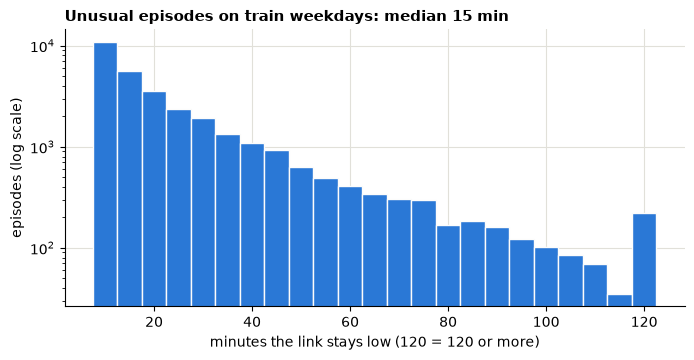

| the link stays low for | share of train episodes |
|---|---|
| 10 min (the shortest possible) | 35% |
| 15 min or more | 65% |
| 20 min or more | 47% |
| 30 min or more | 28% |
| 60 min or more | 8% |

split,heldout_road,episodes,median minutes low
str,bool,u32,f64
"""train""",false,22661,15.0
"""train""",true,8648,15.0
"""validate""",false,7481,15.0
"""validate""",true,3279,15.0


In [6]:
full_ep = (pl.scan_parquet(S.FULL).filter(pl.col("in_population")).select("LinkID", "t", "date", "split", "heldout_road", "U")
             .collect().sort("LinkID", "t"))
ep = (full_ep.with_columns(pl.col("U").cast(pl.Int8).fill_null(-1).alias("st"))
             .with_columns(pl.col("st").shift(1).over("LinkID", "date").alias("prev_st"))
             .with_columns((pl.col("st") != pl.col("prev_st")).fill_null(True).cast(pl.Int32).cum_sum()
                           .over("LinkID", "date").alias("run"))
             .group_by("LinkID", "date", "run")
             .agg(pl.col("st").first(), pl.col("prev_st").first(), pl.len().alias("updates"),
                  pl.col("split").first(), pl.col("heldout_road").first())
             .filter((pl.col("st") == 1) & (pl.col("prev_st") == 0)))
del full_ep
dur = (ep.filter(pl.col("split") == "train")["updates"].to_numpy() + 1) * 5      # minutes the link stays low
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.clip(dur, 10, 120), bins=np.r_[np.arange(10, 125, 5), 125] - 2.5, color=SLOT[0], edgecolor=SURFACE)
ax.set_yscale("log")
ax.set_xlabel("minutes the link stays low (120 = 120 or more)")
ax.set_ylabel("episodes (log scale)")
ax.set_title(f"Unusual episodes on train weekdays: median {np.median(dur):.0f} min")
save(fig, "part2_episode_lengths.png")
mdtable([[f"{m} min" + (" (the shortest possible)" if m == 10 else " or more"),
          f"{(dur == m).mean():.0%}" if m == 10 else f"{(dur >= m).mean():.0%}"] for m in (10, 15, 20, 30, 60)],
        ["the link stays low for", "share of train episodes"])
display(ep.group_by("split", "heldout_road").agg(pl.len().alias("episodes"),
                                                 ((pl.col("updates") + 1) * 5).median().alias("median minutes low"))
          .sort("split", "heldout_road"))

About a third of the episodes are the shortest possible (low for exactly 10 minutes), and only about 3 in 10 last
30 minutes or more. Short dips are therefore a large part of the label: a limitation we report.

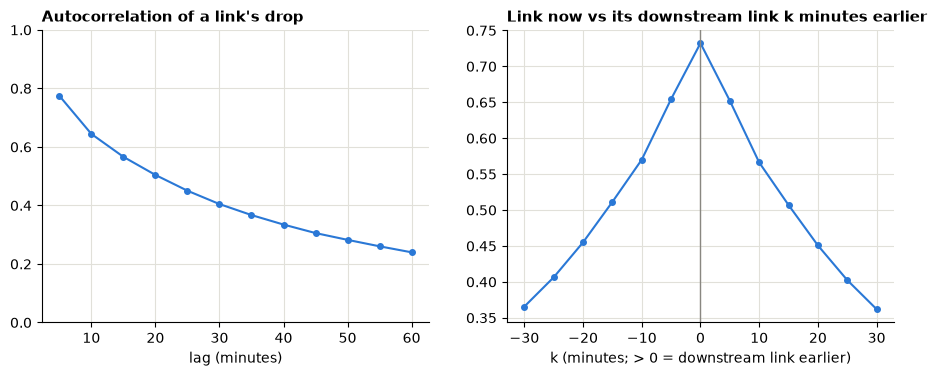

autocorrelation: 5 min 0.77, 15 min 0.57, 30 min 0.40, 60 min 0.24
link now vs downstream link k min earlier: k = -15: 0.511, k = -5: 0.654, k = 0: 0.732, k = 5: 0.652, k = 15: 0.507


In [7]:
d = full.filter(pl.col("info_deficit").is_not_null()).select("LinkID", "t", pl.col("info_deficit").alias("d"))
def corr(a, b):
    return float(np.corrcoef(a, b)[0, 1])
acf = []
for k in range(1, 13):
    j = d.join(d.select("LinkID", (pl.col("t") + timedelta(minutes=5 * k)).alias("t"), pl.col("d").alias("dk")), on=["LinkID", "t"])
    acf.append(corr(j["d"].to_numpy(), j["dk"].to_numpy()))
nb = pl.read_parquet(S.NEIGH)
xc = {}
for k in range(-6, 7):
    j = (nb.select("LinkID", "downstream").join(d, on="LinkID")
           .join(d.select(pl.col("LinkID").alias("downstream"), (pl.col("t") + timedelta(minutes=5 * k)).alias("t"),
                          pl.col("d").alias("dd")), on=["downstream", "t"]))
    xc[5 * k] = corr(j["d"].to_numpy(), j["dd"].to_numpy())
del d, j
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot([5 * k for k in range(1, 13)], acf, color=SLOT[0], marker="o", markersize=4)
axs[0].set_title("Autocorrelation of a link's drop")
axs[0].set_xlabel("lag (minutes)")
axs[0].set_ylim(0, 1)
ks = sorted(xc)
axs[1].plot(ks, [xc[k] for k in ks], color=SLOT[0], marker="o", markersize=4)
axs[1].axvline(0, color=MUTED, linewidth=1)
axs[1].set_title("Link now vs its downstream link k minutes earlier")
axs[1].set_xlabel("k (minutes; > 0 = downstream link earlier)")
save(fig, "part2_dependence.png")
print("autocorrelation: " + ", ".join(f"{5 * k} min {a:.2f}" for k, a in zip(range(1, 13), acf) if k in (1, 3, 6, 12)))
print("link now vs downstream link k min earlier: " + ", ".join(f"k = {k}: {xc[k]:.3f}" for k in (-15, -5, 0, 5, 15)))

Rows are strongly dependent. A link's drop still has an autocorrelation of 0.57 after 15 minutes. A link also moves
with its downstream neighbour (correlation 0.73 at the same update, 0.65 five minutes apart). The right-hand curve is
almost the same on both sides of zero: with 5-minute updates and links of about 140 m, the data do not show which of
the two links moves first. The 8 million rows hold only about 22,000 train episodes on the training roads, and the
evaluation has only a few days. Uncertainty is therefore estimated by resampling **whole days**, never single rows
(Part 3).

## 5. Rain and drift

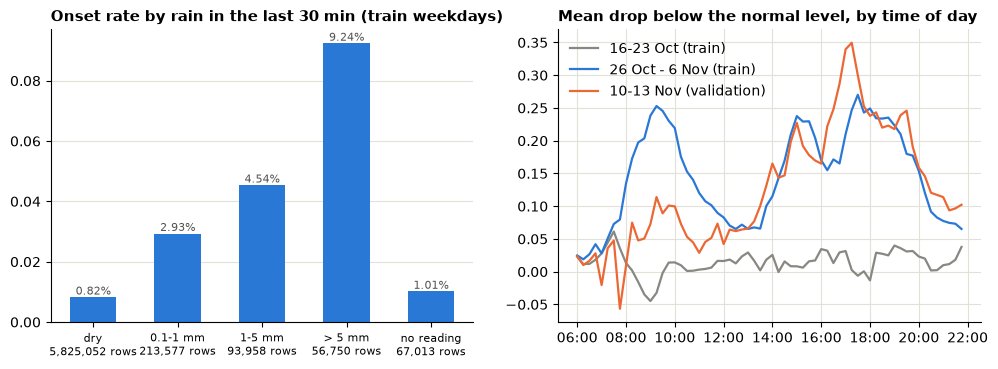

rain,rows,onsets,rate
str,u32,u32,f64
"""dry""",5825052,47929,0.008228
"""0.1-1 mm""",213577,6261,0.029315
"""1-5 mm""",93958,4262,0.045361
"""> 5 mm""",56750,5242,0.09237
"""no reading""",67013,679,0.010132


In [8]:
rain = (use.filter(~pl.col("U") & (pl.col("split") == "train"))
           .with_columns(pl.when(pl.col("f_rain30_missing") == 1).then(pl.lit("no reading"))
                         .when(pl.col("f_rain30") == 0).then(pl.lit("dry"))
                         .when(pl.col("f_rain30") <= 1).then(pl.lit("0.1-1 mm"))
                         .when(pl.col("f_rain30") <= 5).then(pl.lit("1-5 mm"))
                         .otherwise(pl.lit("> 5 mm")).alias("rain"))
           .group_by("rain").agg(pl.len().alias("rows"), pl.col("y").sum().alias("onsets"), pl.col("y").mean().alias("rate")))
order = ["dry", "0.1-1 mm", "1-5 mm", "> 5 mm", "no reading"]
rain = rain.with_columns(pl.col("rain").replace_strict({k: i for i, k in enumerate(order)}).alias("o")).sort("o")
prof = (full.filter(pl.col("info_band").is_not_null())
            .with_columns(pl.when(pl.col("date") <= date(2026, 10, 23)).then(pl.lit("16-23 Oct (train)"))
                          .when(pl.col("date") <= S.TRAIN_DAYS[1]).then(pl.lit("26 Oct - 6 Nov (train)"))
                          .otherwise(pl.lit("10-13 Nov (validation)")).alias("period"))
            .group_by("period", "f_slot15").agg(pl.col("info_deficit").mean().alias("drop")).sort("period", "f_slot15"))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].bar(range(rain.height), rain["rate"].to_numpy(), width=0.55, color=SLOT[0])
axs[0].set_xticks(range(rain.height))
axs[0].set_xticklabels([f"{r}\n{n:,} rows" for r, n in zip(rain["rain"], rain["rows"])], fontsize=8)
for i, v in enumerate(rain["rate"]):
    axs[0].text(i, v, f"{v:.2%}", ha="center", va="bottom", fontsize=8, color=INK2)
axs[0].set_title("Onset rate by rain in the last 30 min (train weekdays)")
axs[0].grid(axis="x", visible=False)
for per, c in (("16-23 Oct (train)", MUTED), ("26 Oct - 6 Nov (train)", SLOT[0]), ("10-13 Nov (validation)", SLOT[1])):
    p = prof.filter(pl.col("period") == per)
    axs[1].plot(p["f_slot15"], p["drop"], color=c, label=per, linewidth=1.6)
axs[1].set_xticks(range(24, 89, 8))
axs[1].set_xticklabels([f"{t // 4:02d}:00" for t in range(24, 89, 8)])
axs[1].set_title("Mean drop below the normal level, by time of day")
axs[1].legend(loc="upper left")
save(fig, "part2_rain_and_drift.png")
display(rain.drop("o"))

Onsets are several times more frequent after rain (an association: rain is one input, not a proven cause). The later
weeks run below the normal level more often than the first week: the normal level is a median over all 16 train days,
so busier weeks look "unusual" more often. This drift is why the models are tuned by **forward-chaining** (fit on
earlier days, check on later days), never by random splits.

## 6. Feature engineering

**The build's 53 inputs** (Part 1, step 5) describe the link itself and its nearest surroundings: its drop now and up
to 30 minutes ago, the largest drop on the links just upstream and downstream, the same for the joining roads, rain,
time of day and day of week.

**We add three groups**, all known at time t and built from train-day information only:

- **NORM, the normal level ahead** - the link's normal level at the slots of t, t + 5, ..., t + 30 (`fe_norm_p0` ...
  `fe_norm_p30`). The normal level of a future slot is fixed in advance, so it is known at t. From it the models get
  the band now and the drop the link *would* have at t + 10 and t + 15 if its band stayed the same ("band
  persistence"): a usual peak that ends on the clock but not on this link.
- **HOP, queues within 3 km** - the links along the road beyond the next link, in three rings ((0, 500], (500, 1500],
  (1500, 3000] m of path), downstream and upstream: the largest drop and the share of low links now and 10 minutes
  ago, and the distance to the nearest low link downstream (the tail of a queue), now and 10 minutes ago. The next
  link alone (`f_dn_*`) sees only about 140 m.
- **HIST, the link's usual onset rate** at that time of day. It uses the answers of the fit rows, so it is fitted
  inside each training window in Part 3, leaving each row's own day out. It is not built here.

The cell below builds NORM and HOP for every weekday row (the same code as `modelling/02_features.py`). The checks
after it: the band now is a whole band 1-8; our next-link maximum equals the build's `f_dn_d0` / `f_up_d0`; 400
random rows recomputed independently (plain Python, shortest paths by repeated relaxation instead of Dijkstra); 300
rows of the future normal level read straight from `norm.parquet`; and the whole table equals the pipeline's.

In [9]:
links_f = pl.read_parquet(S.LINKS).sort("LinkID")
neigh = pl.read_parquet(S.NEIGH)

hop_pairs = F.hop_pairs(links_f, neigh)               # (link, other link, direction, path metres) within 3 km
static = F.hop_static(hop_pairs, links_f["LinkID"].to_list())
assert hop_pairs.filter((pl.col("dist") == 0) & (pl.col("dir") == "dn")).height == neigh.height
log(f"pairs within 3 km of path: {hop_pairs.height:,}")
RING = {0: "next link (0 m)", 1: "(0, 500] m", 2: "(500, 1500] m", 3: "(1500, 3000] m"}
display(hop_pairs.with_columns(F.ring_of(pl.col("dist")).fill_null(0).alias("ring")).group_by("dir", "ring")
        .agg(pl.len().alias("pairs"), pl.col("LinkID").n_unique().alias("links with this ring")).sort("dir", "ring")
        .with_columns(pl.col("ring").replace_strict(RING, return_dtype=pl.Utf8).alias("path distance beyond the next link")))

fdays = sorted(full["date"].unique().to_list())
assert max(fdays) <= LAST and full.height == len(fdays) * 2598 * 192
hop_parts, series = [], []
for d in fdays:
    fd = full.filter(pl.col("date") == d)
    ser = F.dfill_series(fd)                           # every link's (reused <= 5 min) drop at every time
    hop_parts.append(F.hop_features(fd.select("LinkID", "t"), F.hop_day(ser, hop_pairs)))
    series.append(ser)
hopf, ser = pl.concat(hop_parts), pl.concat(series)
del hop_parts, series
fe = (full.select("LinkID", "t").join(F.norm_features(full.select("LinkID", "t"), norm_w), on=["LinkID", "t"],
                                      how="left", maintain_order="left")
          .join(hopf, on=["LinkID", "t"], how="left", maintain_order="left")
          .join(static, on="LinkID", how="left", maintain_order="left").sort("LinkID", "t"))
fe_cols = [c for c in fe.columns if c.startswith("fe_")]
assert fe.select(pl.col(fe_cols).null_count()).sum_horizontal().item() == 0
log(f"engineered inputs: {fe.height:,} rows (20 weekdays x 2,598 links x 192 updates) x {len(fe_cols)} columns")

[   30 s] pairs within 3 km of path: 121,766


dir,ring,pairs,links with this ring,path distance beyond the next link
str,i8,u32,u32,str
"""dn""",0,2596,2571,"""next link (0 m)"""
"""dn""",1,8994,2548,"""(0, 500] m"""
"""dn""",2,19988,2489,"""(500, 1500] m"""
"""dn""",3,29305,2398,"""(1500, 3000] m"""
"""up""",0,2596,2578,"""next link (0 m)"""
"""up""",1,8994,2561,"""(0, 500] m"""
"""up""",2,19988,2510,"""(500, 1500] m"""
"""up""",3,29305,2422,"""(1500, 3000] m"""


[   78 s] engineered inputs: 9,976,320 rows (20 weekdays x 2,598 links x 192 updates) x 40 columns


In [10]:
checks = []
u = full.join(fe.select("LinkID", "t", "fe_norm_p0"), on=["LinkID", "t"]).filter(pl.col("use"))
band = (u["fe_norm_p0"] - u["f_d0"]).to_numpy()
checks.append(["band now = fe_norm_p0 - f_d0 is a whole band 1-8 (usable rows)",
               bool(np.all((band >= 1) & (band <= 8) & (band == np.round(band))))])
for direction, col in (("dn", "f_dn_d0"), ("up", "f_up_d0")):
    nxt = (hop_pairs.filter((pl.col("dist") == 0) & (pl.col("dir") == direction))
                    .join(ser.rename({"LinkID": "other"}), on="other").group_by("LinkID", "s").agg(pl.col("v").max().alias("mx")))
    cmp = (u.select("LinkID", "t", col).join(nxt.rename({"s": "t"}), on=["LinkID", "t"], how="left")
            .with_columns(pl.col("mx").fill_null(0.0)))
    checks.append([f"next-link maximum == the build's {col} (usable rows)",
                   cmp.filter((pl.col(col) - pl.col("mx")).abs() > 1e-6).height == 0])
# independent recomputation of 400 random rows: plain Python dictionaries, Bellman-Ford style shortest paths
length = dict(F.link_geometry(links_f).iter_rows())
down, up = {}, {}
for a_, b_ in neigh.select("LinkID", "downstream").iter_rows():
    down.setdefault(a_, []).append(b_)
    up.setdefault(b_, []).append(a_)
sample = fe.select("LinkID", "t", *fe_cols).sample(400, seed=11)
need_s = pl.concat([sample.select((pl.col("t") - timedelta(minutes=lag)).alias("s")) for lag in (0, 10)]).unique()
vmap = {(l, s): v for l, s, v in ser.join(need_s, on="s").iter_rows()}
def reach(l, graph):
    dist = {b: 0.0 for b in graph.get(l, []) if b != l}
    changed = True
    while changed:
        changed = False
        for b, dd in list(dist.items()):
            for c in graph.get(b, []):
                nd = dd + length[b]
                if c != l and nd <= 3000.0 and nd < dist.get(c, 1e18):
                    dist[c], changed = nd, True
    return dist
ci_ = {c: i + 2 for i, c in enumerate(fe_cols)}
bad = 0
for r in sample.iter_rows():
    l, t = r[0], r[1]
    for direction, graph in (("dn", down), ("up", up)):
        dist = reach(l, graph)
        for lag in (0, 10):
            s = t - timedelta(minutes=lag)
            for k, (lo, hi) in enumerate(((0, 500), (500, 1500), (1500, 3000)), start=1):
                vals = [v for v in (vmap.get((b, s)) for b, dd in dist.items() if lo < dd <= hi) if v is not None]
                bad += abs(r[ci_[f"fe_{direction}_r{k}_max{lag}"]] - (max(vals) if vals else 0.0)) > 1e-6
                bad += abs(r[ci_[f"fe_{direction}_r{k}_low{lag}"]] - (sum(v >= 2 for v in vals) / len(vals) if vals else 0.0)) > 1e-6
            if direction == "dn" or lag == 0:
                qs = [dd for b, dd in dist.items() if vmap.get((b, s)) is not None and vmap[(b, s)] >= 2]
                bad += abs(r[ci_[f"fe_{direction}_q{lag}"]] - (min(qs) if qs else 3500.0)) > 1e-3
checks.append(["HOP values of 400 random rows recomputed independently", bad == 0])
nd_ = {(l, s): v for l, s, v in norm_w.select("LinkID", "slot15", "norm_band").iter_rows()}
bad = 0
for l, t, *vals in fe.select("LinkID", "t", *[f"fe_norm_p{k}" for k in F.NORM_OFFSETS]).sample(300, seed=3).iter_rows():
    for k, v in zip(F.NORM_OFFSETS, vals):
        tk = t + timedelta(minutes=k)
        bad += abs(nd_[(l, tk.hour * 4 + tk.minute // 15)] - v) > 1e-6
checks.append(["fe_norm_p{k} == norm.parquet at the slot of t + k (300 rows x 6)", bad == 0])
saved = pl.read_parquet(S.WORK / "fe_trainval.parquet")           # written by modelling/02_features.py
checks.append(["equal to the pipeline's table (modelling/02_features.py)", fe.equals(saved.select(fe.columns))])
mdtable([[a_, "OK" if b_ else "FAIL"] for a_, b_ in checks], ["check", "result"])
assert all(b_ for _, b_ in checks)
del saved, ser, hopf
print("columns:", ", ".join(fe_cols))

| check | result |
|---|---|
| band now = fe_norm_p0 - f_d0 is a whole band 1-8 (usable rows) | OK |
| next-link maximum == the build's f_dn_d0 (usable rows) | OK |
| next-link maximum == the build's f_up_d0 (usable rows) | OK |
| HOP values of 400 random rows recomputed independently | OK |
| fe_norm_p{k} == norm.parquet at the slot of t + k (300 rows x 6) | OK |
| equal to the pipeline's table (modelling/02_features.py) | OK |

columns: fe_norm_p0, fe_norm_p5, fe_norm_p10, fe_norm_p15, fe_norm_p25, fe_norm_p30, fe_dn_r1_max0, fe_dn_r1_low0, fe_dn_r2_max0, fe_dn_r2_low0, fe_dn_r3_max0, fe_dn_r3_low0, fe_up_r1_max0, fe_up_r1_low0, fe_up_r2_max0, fe_up_r2_low0, fe_up_r3_max0, fe_up_r3_low0, fe_dn_q0, fe_up_q0, fe_dn_r1_max10, fe_dn_r1_low10, fe_dn_r2_max10, fe_dn_r2_low10, fe_dn_r3_max10, fe_dn_r3_low10, fe_up_r1_max10, fe_up_r1_low10, fe_up_r2_max10, fe_up_r2_low10, fe_up_r3_max10, fe_up_r3_low10, fe_dn_q10, fe_dn_qmove, fe_dn_r1_none, fe_dn_r2_none, fe_dn_r3_none, fe_up_r1_none, fe_up_r2_none, fe_up_r3_none


## 7. What comes before an onset? (Why these inputs should help)

Train weekdays, training roads, rows that are normal now. The engineered inputs are the ones built in section 6.

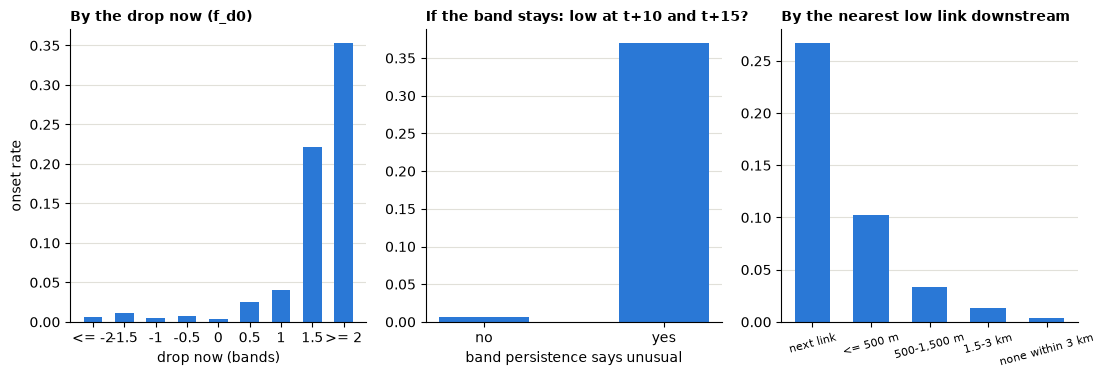

onsets that start from a link at or above its normal level (f_d0 <= 0): 35.1%


band persistence says unusual (1 = yes),rows,onsets,rate
f32,u32,u32,f64
0.0,4542843,30266,0.0067
1.0,43708,16156,0.3696


nearest low link downstream,rows,onsets,rate
str,u32,u32,f64
"""next link""",52833,14101,0.2669
"""<= 500 m""",90689,9293,0.1025
"""500-1,500 m""",159517,5360,0.0336
"""1.5-3 km""",199494,2661,0.0133
"""none within 3 km""",4084018,15007,0.0037


In [11]:
on = (use.filter(~pl.col("U") & (pl.col("split") == "train") & ~pl.col("heldout_road"))
         .select("LinkID", "t", "y", "f_d0", "f_d5")
         .join(fe.select("LinkID", "t", "fe_norm_p0", "fe_norm_p10", "fe_norm_p15", "fe_dn_q0"), on=["LinkID", "t"], how="left"))
on = F.add_derived(on, 15)
d0 = (on.with_columns(pl.col("f_d0").clip(-2, 2).alias("d0b")).group_by("d0b")
        .agg(pl.len().alias("rows"), pl.col("y").sum().alias("onsets"), pl.col("y").mean().alias("rate")).sort("d0b"))
lp = on.group_by("x_lowpers15").agg(pl.len().alias("rows"), pl.col("y").sum().alias("onsets"),
                                    pl.col("y").mean().alias("rate")).sort("x_lowpers15")
qorder = ["next link", "<= 500 m", "500-1,500 m", "1.5-3 km", "none within 3 km"]
qb = (on.with_columns(pl.when(pl.col("fe_dn_q0") == 0).then(pl.lit("next link"))
                        .when(pl.col("fe_dn_q0") <= 500).then(pl.lit("<= 500 m"))
                        .when(pl.col("fe_dn_q0") <= 1500).then(pl.lit("500-1,500 m"))
                        .when(pl.col("fe_dn_q0") <= 3000).then(pl.lit("1.5-3 km"))
                        .otherwise(pl.lit("none within 3 km")).alias("q"))
        .group_by("q").agg(pl.len().alias("rows"), pl.col("y").sum().alias("onsets"), pl.col("y").mean().alias("rate")))
qb = qb.with_columns(pl.col("q").replace_strict({k: i for i, k in enumerate(qorder)}).alias("o")).sort("o")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
lab = [f"{v:g}" if -2 < v < 2 else ("<= -2" if v <= -2 else ">= 2") for v in d0["d0b"]]
axs[0].bar(range(d0.height), d0["rate"].to_numpy(), color=SLOT[0], width=0.6)
axs[0].set_xticks(range(d0.height))
axs[0].set_xticklabels(lab)
axs[0].set_title("By the drop now (f_d0)", fontsize=10)
axs[0].set_xlabel("drop now (bands)")
axs[0].set_ylabel("onset rate")
axs[1].bar([0, 1], lp["rate"].to_numpy(), color=SLOT[0], width=0.5)
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels(["no", "yes"])
axs[1].set_title("If the band stays: low at t+10 and t+15?", fontsize=10)
axs[1].set_xlabel("band persistence says unusual")
axs[2].bar(range(qb.height), qb["rate"].to_numpy(), color=SLOT[0], width=0.6)
axs[2].set_xticks(range(qb.height))
axs[2].set_xticklabels(qorder, fontsize=8, rotation=15)
axs[2].set_title("By the nearest low link downstream", fontsize=10)
for ax in axs:
    ax.grid(axis="x", visible=False)
save(fig, "part2_precursors.png")
print(f"onsets that start from a link at or above its normal level (f_d0 <= 0): "
      f"{on.filter(pl.col('y') & (pl.col('f_d0') <= 0)).height / on['y'].sum():.1%}")
display(lp.with_columns(pl.col("rate").round(4)).rename({"x_lowpers15": "band persistence says unusual (1 = yes)"}))
display(qb.drop("o").with_columns(pl.col("rate").round(4)).rename({"q": "nearest low link downstream"}))

Three signs stand out, and each became an input group:

- **The drop now** (`f_d0`): the onset rate rises steeply with it, but about a third of onsets start from a link that
  is at or above its normal level, which "last observation" cannot rank.
- **The normal level ahead** (NORM): when the link's band would already count as low at t + 10 and t + 15 because its
  usual level is about to rise (a peak ending on the clock but not on this link), the onset rate is about 37% instead
  of under 1%.
- **Queues downstream** (HOP): the onset rate falls steadily with the distance to the nearest low link downstream,
  out to 3 km, far beyond the next link that the 53 build inputs see.

**The figure for the report.** Two of the findings, drawn at the size they have on the page of the report: why the
label compares a link with its own normal level (section 2), and why the inputs look further down the road (above).

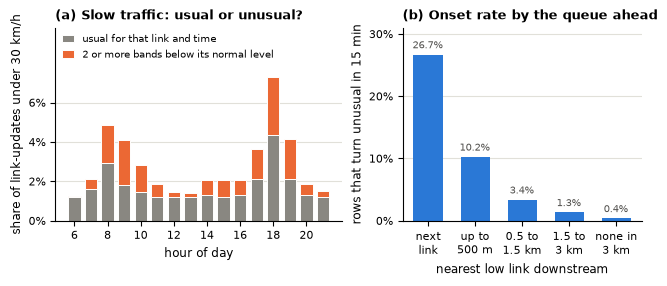

(a) share of slow link-updates that are usual for that link and time: 61.7%
(b) onset rate: next link 26.7%, <= 500 m 10.2%, 500-1,500 m 3.4%, 1.5-3 km 1.3%, none within 3 km 0.4%


In [12]:
with plt.rc_context({"font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5, "xtick.labelsize": 8, "ytick.labelsize": 8}):
    fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.75), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1.0]})
    hh = slow["hour"].to_numpy()
    r_, u_ = (slow["recurring"] / slow["n"]).to_numpy(), (slow["unusual"] / slow["n"]).to_numpy()
    axs[0].bar(hh, r_, width=0.74, color=MUTED, edgecolor="white", linewidth=0.7, label="usual for that link and time")
    axs[0].bar(hh, u_, bottom=r_, width=0.74, color=SLOT[1], edgecolor="white", linewidth=0.7,
               label="2 or more bands below its normal level")
    axs[0].set_xticks(range(6, 22, 2))
    axs[0].set_xticklabels([str(x) for x in range(6, 22, 2)])
    axs[0].set_yticks([0, 0.02, 0.04, 0.06])
    axs[0].set_yticklabels(["0%", "2%", "4%", "6%"])
    axs[0].set_ylim(0, 0.098)
    axs[0].set_xlabel("hour of day")
    axs[0].set_ylabel("share of link-updates under 30 km/h")
    axs[0].legend(loc="upper left", fontsize=7.5, handlelength=1.2, borderaxespad=0.2)
    axs[0].grid(axis="x", visible=False)
    axs[0].set_title("(a) Slow traffic: usual or unusual?")
    rate = qb["rate"].to_numpy()
    axs[1].bar(range(qb.height), rate, width=0.62, color=SLOT[0])
    for i, v in enumerate(rate):
        axs[1].text(i, v + 0.006, f"{v:.1%}", ha="center", va="bottom", fontsize=7.5, color=INK2)
    axs[1].set_xticks(range(qb.height))
    axs[1].set_xticklabels(["next\nlink", "up to\n500 m", "0.5 to\n1.5 km", "1.5 to\n3 km", "none in\n3 km"])
    axs[1].set_yticks([0, 0.1, 0.2, 0.3])
    axs[1].set_yticklabels(["0%", "10%", "20%", "30%"])
    axs[1].set_ylim(0, 0.31)
    axs[1].set_xlabel("nearest low link downstream")
    axs[1].set_ylabel("rows that turn unusual in 15 min")
    axs[1].grid(axis="x", visible=False)
    axs[1].set_title("(b) Onset rate by the queue ahead")
    save(fig, "report_fig1_exploration.png")
print("(a) share of slow link-updates that are usual for that link and time: "
      f"{slow['recurring'].sum() / (slow['recurring'].sum() + slow['unusual'].sum()):.1%}")
print("(b) onset rate: " + ", ".join(f"{q} {v:.1%}" for q, v in zip(qorder, rate)))

## 8. Three kinds of onset, from what is known at the time of prediction

Every row that is normal now is put in exactly one group, using **only information available at time t** (so the
grouping can never use the outcome). The rules were fixed before any model was scored by group:

- **A, forming here**: the link is already below its normal level (`f_d0 > 0`), or band persistence says it will be
  unusual at t + 15 (`x_lowpers15 = 1`);
- **B, queue ahead**: not A, and a link up to 500 m downstream is low now (`fe_dn_q0 <= 500`);
- **C, new**: neither: the road ahead and the link itself look normal.

In [13]:
grp = (pl.when((pl.col("f_d0") > 0) | (pl.col("x_lowpers15") == 1)).then(pl.lit("A forming here"))
         .when(pl.col("fe_dn_q0") <= 500).then(pl.lit("B queue ahead")).otherwise(pl.lit("C new")))
g = (on.with_columns(grp.alias("group")).group_by("group")
       .agg(pl.len().alias("rows"), pl.col("y").sum().alias("onsets"), pl.col("y").mean().alias("onset rate"))
       .with_columns((pl.col("rows") / pl.col("rows").sum()).alias("share of rows"),
                     (pl.col("onsets") / pl.col("onsets").sum()).alias("share of onsets"))
       .sort("group"))
mdtable([[r["group"], f"{r['rows']:,}", f"{r['share of rows']:.1%}", f"{r['onsets']:,}", f"{r['share of onsets']:.1%}",
          f"{r['onset rate']:.4f}"] for r in g.iter_rows(named=True)],
        ["group (train weekdays, training roads)", "rows", "share of rows", "onsets", "share of onsets", "onset rate"])

| group (train weekdays, training roads) | rows | share of rows | onsets | share of onsets | onset rate |
|---|---|---|---|---|---|
| A forming here | 486,997 | 10.6% | 31,315 | 67.5% | 0.0643 |
| B queue ahead | 65,581 | 1.4% | 4,942 | 10.6% | 0.0754 |
| C new | 4,033,973 | 88.0% | 10,165 | 21.9% | 0.0025 |

About 4 in 5 onsets (groups A and B, only 12% of the rows) already show a sign at time t: the slowdown is forming
on the link itself, or a queue is just ahead of it. About 1 in 5 onsets (group C) start on a link and road that look
normal; they are spread over 88% of the rows, so their onset rate is only 0.25%. Part 3 scores the models within
each group: this separates **where slowdowns spread**, which the data can predict, from **genuinely new slowdowns**,
which they hardly can.

## Summary: what the EDA decided

| Finding | Decision |
|---|---|
| most slow traffic is the usual rush hour | label = unusual for that link and time (2 bands below its own normal level, twice in a row) |
| onsets are rare (about 1%) and their rate drifts by week and road | PR-AUC on the same rows; forward-chaining folds; calibration checked on the validation week |
| rows are strongly dependent; few days | uncertainty by resampling whole days |
| the normal level ahead and queues up to 3 km downstream precede onsets | engineered input groups NORM and HOP (and each link's usual onset rate, HIST) |
| a minority of onsets have no sign at time t | report results by kind of onset (A / B / C) |
| short dips are common; band 1-2 links cannot show a 2-band drop | limitations of the label |